# 00 — Look at the data
Train images and their ground-truth masks, per method and per regime
(`full_watermark=False` → *partial*: a watermarked rectangle in a clean image;
`full_watermark=True` → *full*: whole image watermarked, then some regions restored to clean).
Everything here is recomputed from the files, nothing is copied from chat.

In [1]:
import sys; sys.path.insert(0, '..')
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy import ndimage as ndi
import data, metrics
pd.set_option('display.width', 140)
df = data.train_table()
gts = data.train_masks128()
ds = data.load_split('train')
idx = {m['image_name']: i for i, m in enumerate(ds.meta)}
df.head()

,name,method,full_watermark,regime,wm_frac,fold
0,8d350a3ade55,pixelseal,True,full,0.605225,1
1,3ae884409dc3,stegastamp,True,full,0.859558,0
2,63ab2489dca0,pixelseal,True,full,0.960327,2
3,d7759cebfa93,stegastamp,False,partial,0.020508,0
4,a476ade3e703,stegastamp,True,full,0.625732,0


## 1. How many images of each kind

In [2]:
pd.crosstab(df.method, df.regime, margins=True)

regime,full,partial,All
method,,,
pixelseal,85,85,170
stegastamp,85,85,170
trustmark,85,85,170
All,255,255,510


## 2. Watermarked fraction of each image (128 grid)

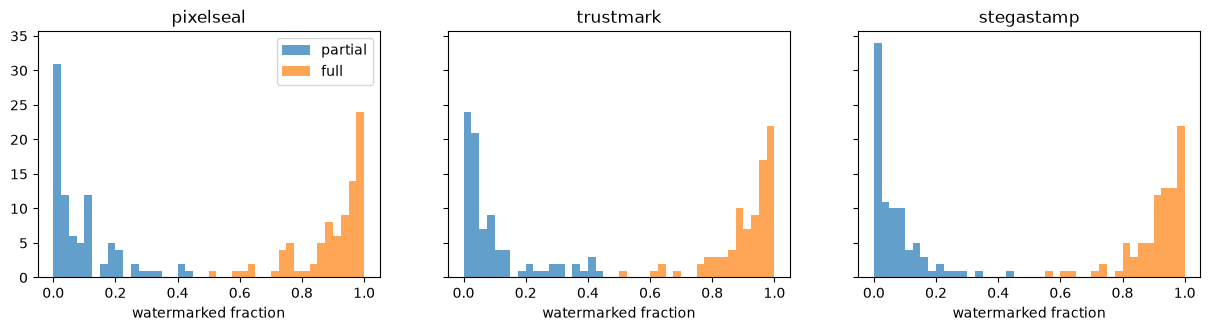

count   mean    std    min    25%    50%    75%    max
method     regime                                                         
pixelseal  full      85.0  0.897  0.109  0.519  0.859  0.941  0.977  0.997
           partial   85.0  0.091  0.103  0.003  0.012  0.049  0.119  0.436
stegastamp full      85.0  0.912  0.087  0.565  0.885  0.936  0.976  0.997
           partial   85.0  0.072  0.081  0.004  0.018  0.037  0.099  0.439
trustmark  full      85.0  0.908  0.097  0.507  0.882  0.944  0.978  0.997
           partial   85.0  0.099  0.118  0.004  0.021  0.044  0.115  0.435

In [3]:
fig, axs = plt.subplots(1, 3, figsize=(15, 3.2), sharey=True)
for ax, m in zip(axs, data.METHODS):
    for r, c in [('partial', 'tab:blue'), ('full', 'tab:orange')]:
        ax.hist(df[(df.method == m) & (df.regime == r)].wm_frac, bins=np.linspace(0, 1, 41), color=c, alpha=.7, label=r)
    ax.set_title(m); ax.set_xlabel('watermarked fraction')
axs[0].legend(); plt.show()
df.groupby(['method', 'regime']).wm_frac.describe().round(3)

## 3. Gallery
For each method × regime, 5 random images. Top: image with the **watermarked** area tinted red.
Bottom: the official 128×128 mask (white = watermarked).

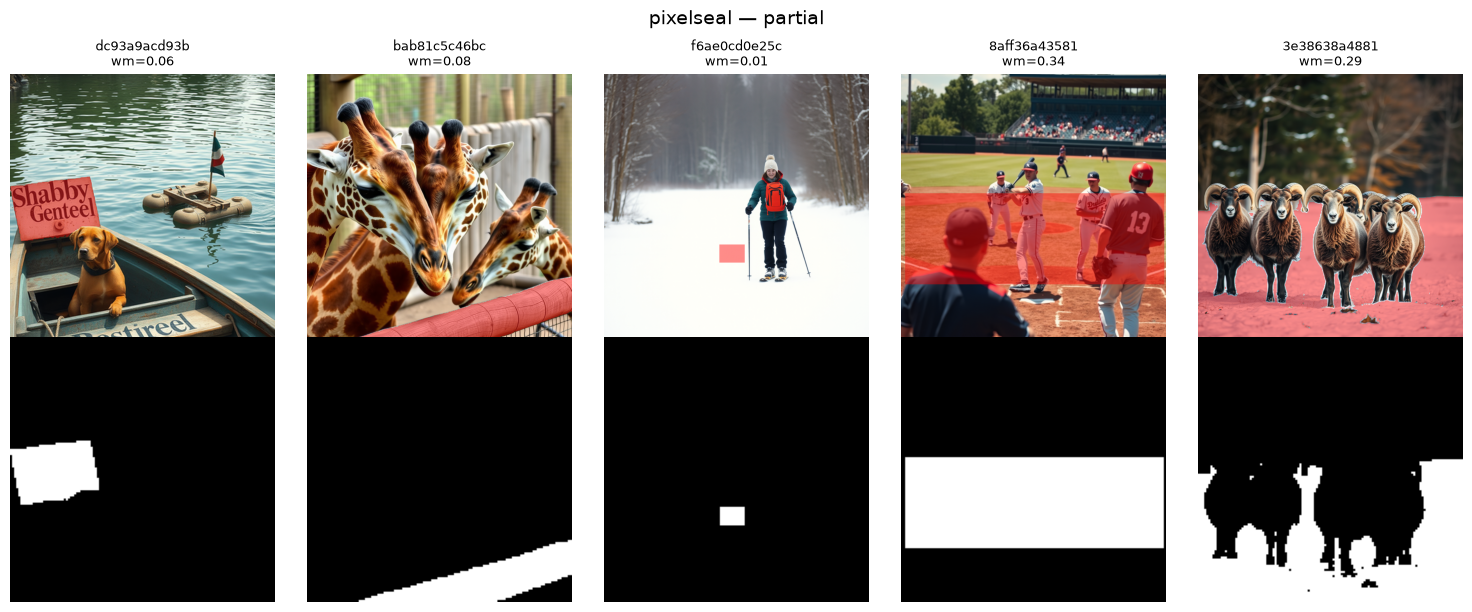

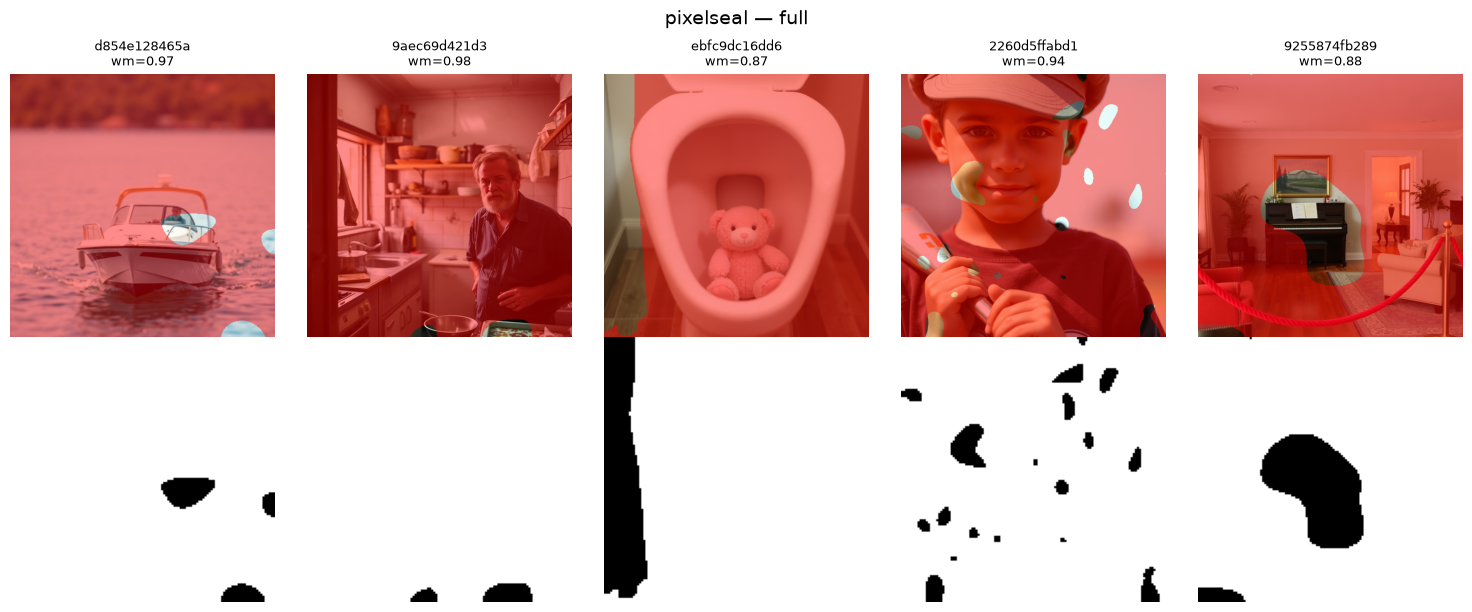

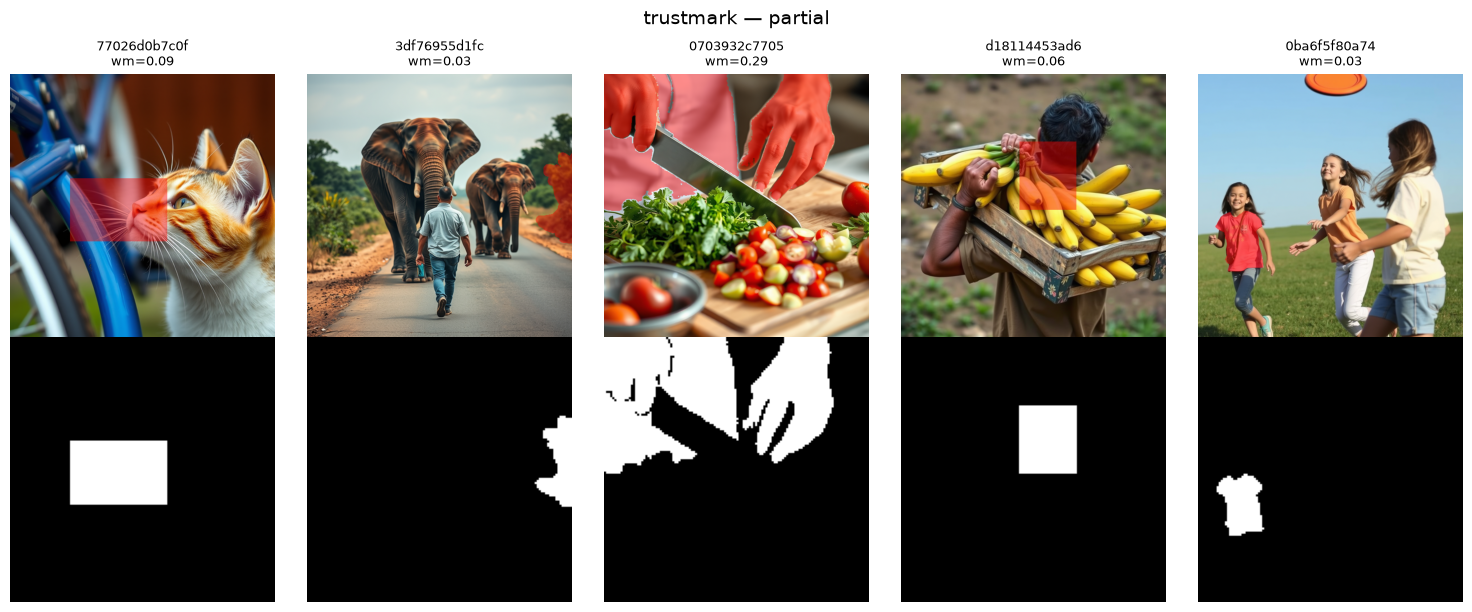

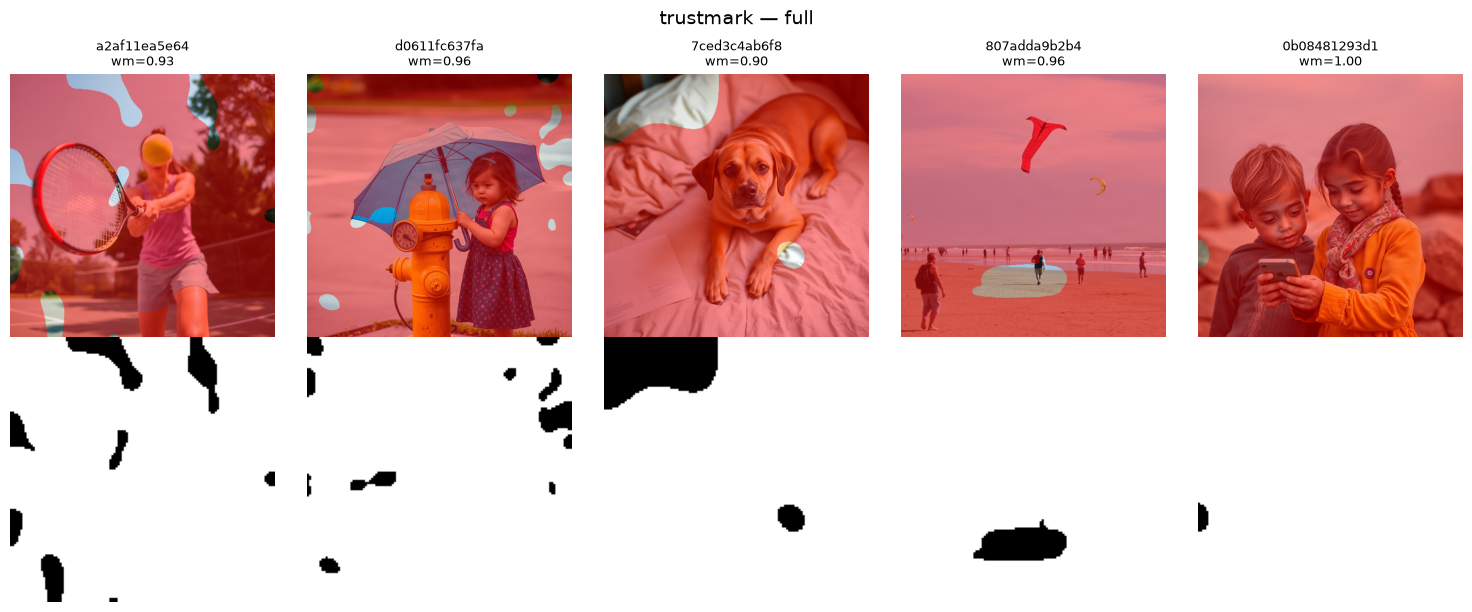

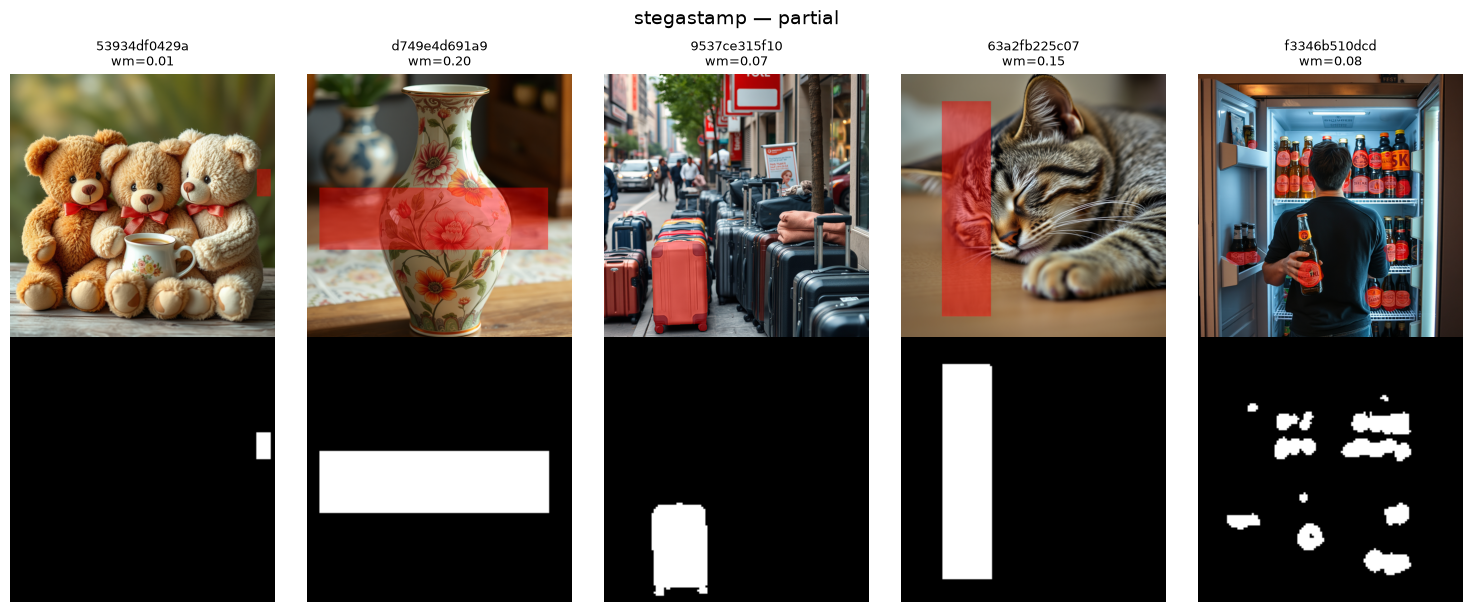

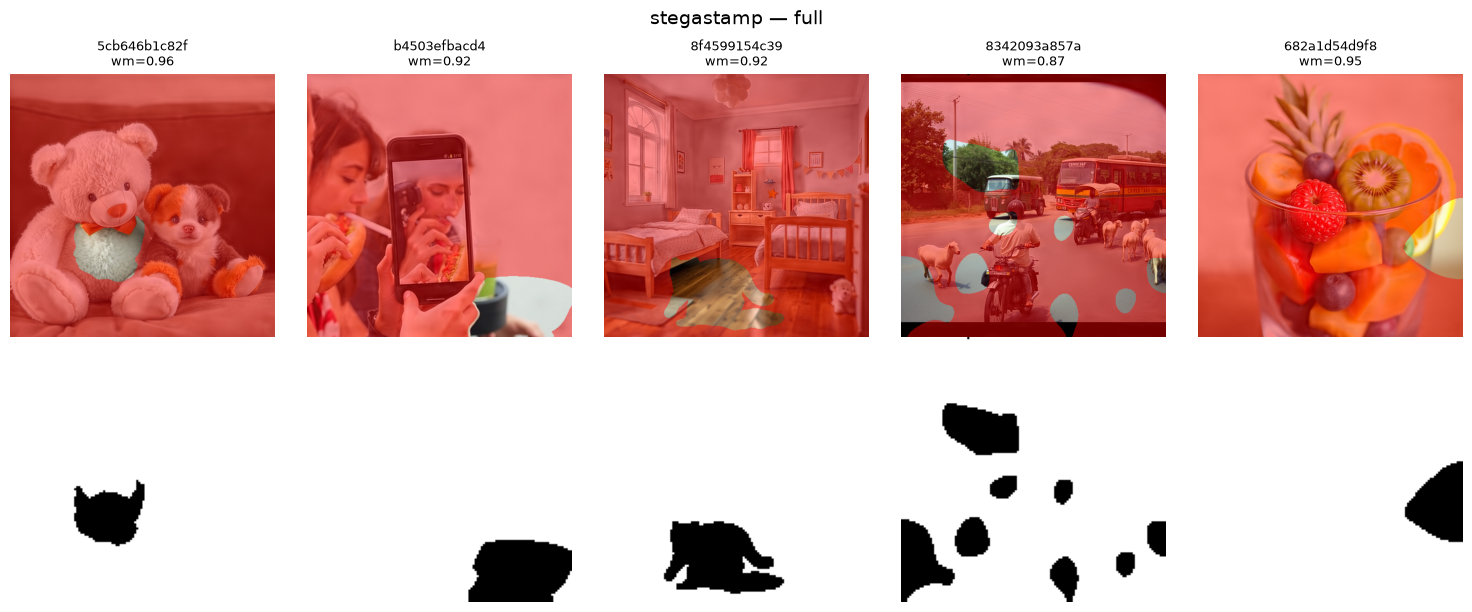

In [4]:
def gallery(method, regime, n=5, seed=0):
    names = df[(df.method == method) & (df.regime == regime)].sample(n, random_state=seed).name
    fig, axs = plt.subplots(2, n, figsize=(3 * n, 6.2))
    for j, name in enumerate(names):
        it = ds[idx[name]]
        over = it['image'].astype(float) / 255
        over[it['mask'] == 1] = 0.55 * over[it['mask'] == 1] + 0.45 * np.array([1, 0, 0])
        axs[0, j].imshow(over); axs[0, j].set_title(f'{name}\nwm={gts[name].mean():.2f}', fontsize=9)
        axs[1, j].imshow(gts[name], cmap='gray', vmin=0, vmax=1)
        for a in axs[:, j]: a.axis('off')
    fig.suptitle(f'{method} — {regime}', fontsize=14); plt.tight_layout(); plt.show()

for m in data.METHODS:
    for r in ('partial', 'full'):
        gallery(m, r)

## 4. Shape of the minority region
Minority region = watermarked area for *partial*, clean area for *full*.
`bbox_fill` = share of its bounding box that it covers (1.0 = a perfect rectangle);
`n_comp` = number of connected pieces; `aspect` = long/short side of the bounding box.

In [5]:
def shape_stats(name, full):
    g = gts[name]; c = (1 - g) if full else g
    lab, n = ndi.label(c)
    ys, xs = np.nonzero(c)
    h, w = ys.ptp() + 1, xs.ptp() + 1
    return dict(minority_area=c.mean(), bbox_fill=c[ys.min():ys.max()+1, xs.min():xs.max()+1].mean(),
                n_comp=n, aspect=max(h, w) / min(h, w))
st = pd.concat([df, pd.DataFrame([shape_stats(r.name, r.full_watermark) for r in df.itertuples()])], axis=1)
st.groupby(['method', 'regime'])[['minority_area', 'bbox_fill', 'n_comp', 'aspect']].median().round(3)

minority_area  bbox_fill  n_comp  aspect
method     regime                                           
pixelseal  full             0.059      0.469     2.0   1.455
           partial          0.049      0.974     1.0   2.154
stegastamp full             0.064      0.518     2.0   1.393
           partial          0.037      0.981     1.0   2.060
trustmark  full             0.056      0.408     2.0   1.273
           partial          0.044      0.983     1.0   1.463

### 4a. What kind of shape is the watermarked region in *partial* images?
Rough rule: `bbox_fill ≥ 0.9` → axis-aligned rectangle; 0.6–0.9 in one piece → rotated or clipped rectangle;
otherwise → object-shaped (e.g. a watermarked object transplanted into a clean image).

In [6]:
p = st[st.regime == 'partial'].copy()
p['kind'] = np.select([p.bbox_fill >= 0.9, (p.bbox_fill >= 0.6) & (p.n_comp == 1)],
                      ['rectangle', 'rotated/clipped rect'], 'object-shaped')
pd.crosstab(p.method, p.kind, margins=True)

kind,object-shaped,rectangle,rotated/clipped rect,All
method,,,,
pixelseal,29,45,11,85
stegastamp,32,44,9,85
trustmark,27,44,14,85
All,88,133,34,255


### 4b. Partial images that are *not* clean rectangles (lowest `bbox_fill`)

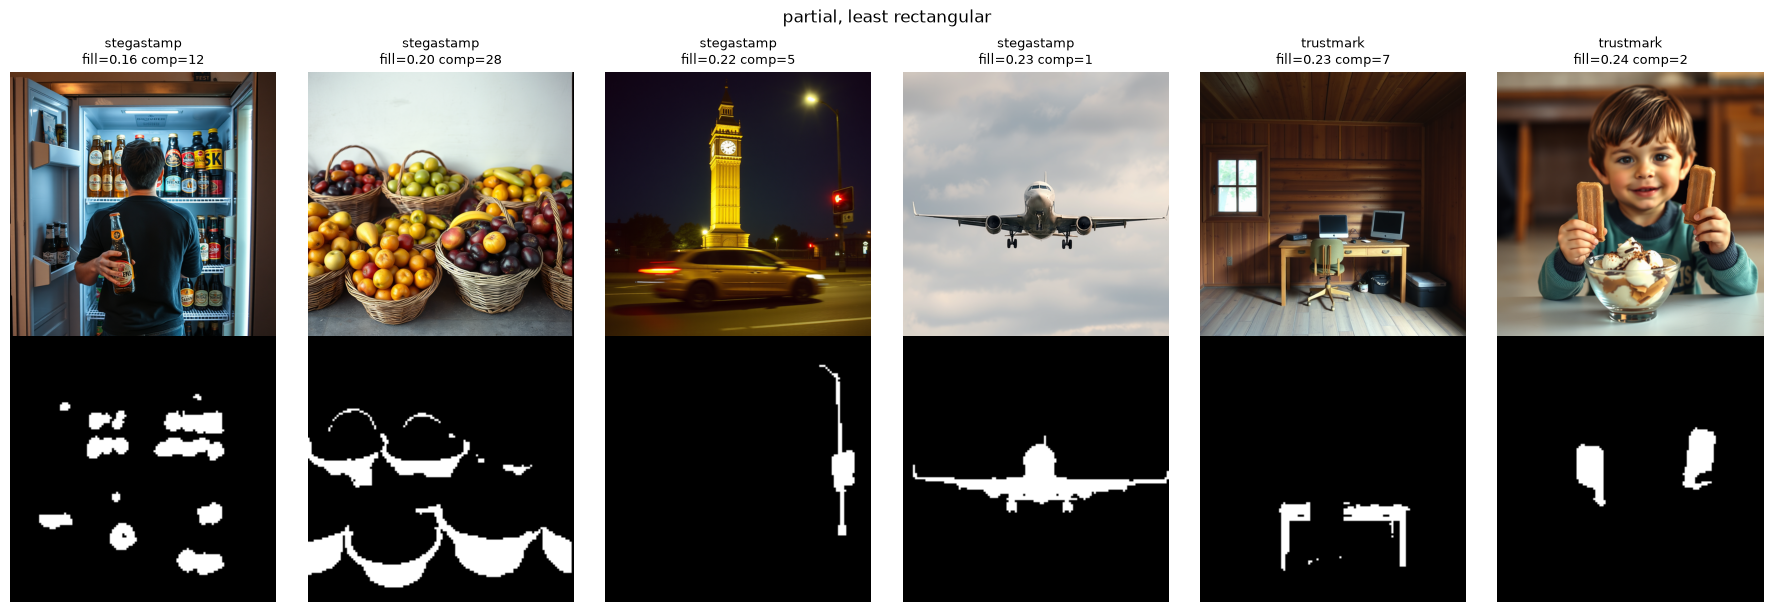

In [7]:
def show(names, title):
    fig, axs = plt.subplots(2, len(names), figsize=(3 * len(names), 6.2))
    for j, name in enumerate(names):
        it = ds[idx[name]]; r = st[st.name == name].iloc[0]
        axs[0, j].imshow(it['image']); axs[0, j].set_title(f'{r.method}\nfill={r.bbox_fill:.2f} comp={r.n_comp}', fontsize=9)
        axs[1, j].imshow(gts[name], cmap='gray', vmin=0, vmax=1)
        for a in axs[:, j]: a.axis('off')
    fig.suptitle(title); plt.tight_layout(); plt.show()
show(st[st.regime == 'partial'].nsmallest(6, 'bbox_fill').name.tolist(), 'partial, least rectangular')

### 4c. TrustMark partial images with aspect > 2
The task says TrustMark rectangles have aspect ≤ 2:1 — check whether the masks agree.

14 of 85 TrustMark partial images have aspect > 2.2


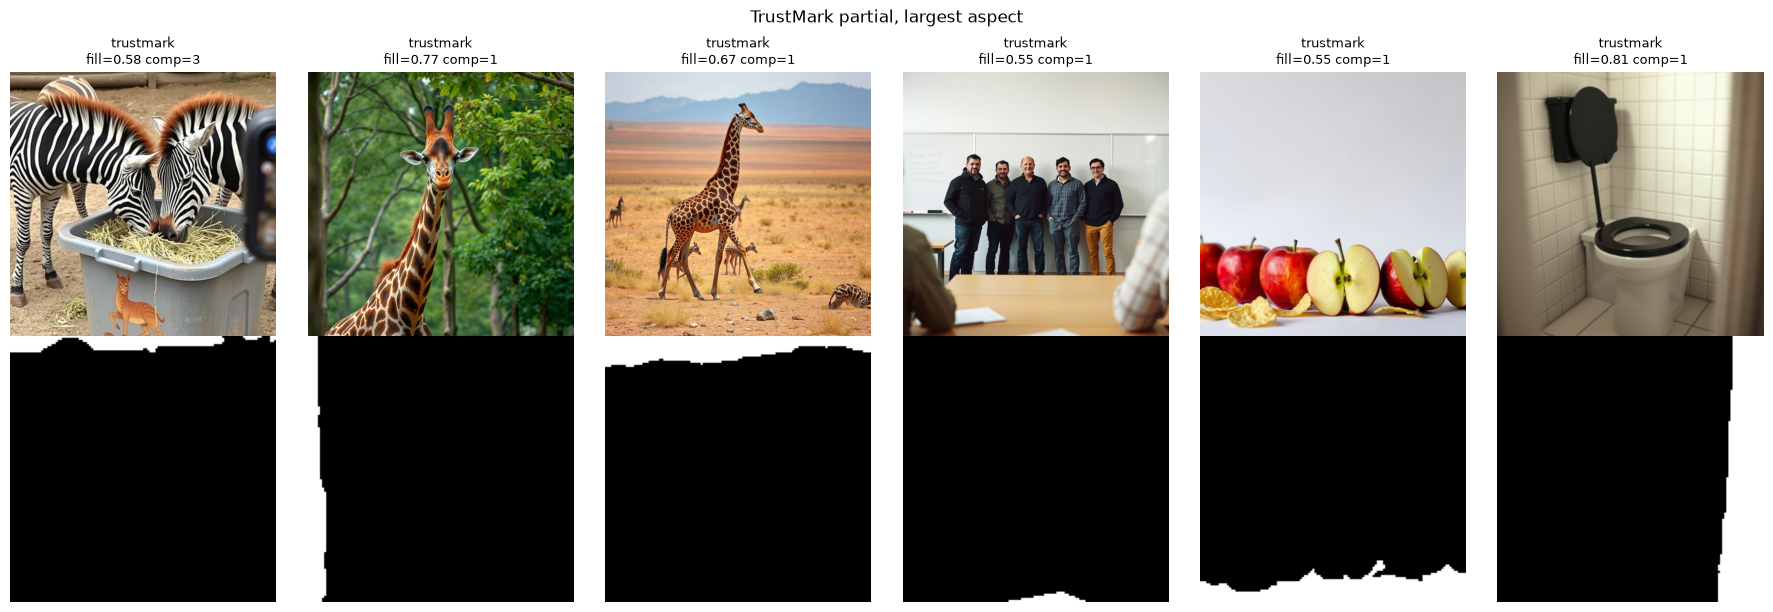

In [8]:
odd = st[(st.method == 'trustmark') & (st.regime == 'partial') & (st.aspect > 2.2)]
print(len(odd), 'of', ((st.method == 'trustmark') & (st.regime == 'partial')).sum(), 'TrustMark partial images have aspect > 2.2')
if len(odd): show(odd.nlargest(6, 'aspect').name.tolist(), 'TrustMark partial, largest aspect')

## 5. Constant baselines (official mIoU on train, from `baselines.py`)

In [9]:
res = pd.read_csv(data.RESULTS / 'step0_baselines.csv')
for b, g in res.groupby('baseline', sort=False):
    print('==', b); display(metrics.breakdown(g))

== all-0


regime,full,partial,all
method,,,
pixelseal,0.0514,0.4547,0.2530
stegastamp,0.0439,0.4641,0.2540
trustmark,0.0460,0.4507,0.2484
ALL,0.0471,0.4565,0.2518


== all-1


regime,full,partial,all
method,,,
pixelseal,0.4486,0.0453,0.2470
stegastamp,0.4561,0.0359,0.2460
trustmark,0.4540,0.0493,0.2516
ALL,0.4529,0.0435,0.2482


== oracle regime (not submittable)


regime,full,partial,all
method,,,
pixelseal,0.4486,0.4547,0.4516
stegastamp,0.4561,0.4641,0.4601
trustmark,0.4540,0.4507,0.4523
ALL,0.4529,0.4565,0.4547
